In [1]:
!pip install yfinance
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
 import yfinance as yf
 import pandas as pd

 tickers=['AAPL','GOOG','MSFT']

 data=yf.download(tickers, start='2022-01-01', end='2025-01-01', auto_adjust=False)

 if data is None or data.empty:
    print("No data download. Please check internet or ticker symbols.")
 else:
     print("Data successfully downloaded!")
     print("Data type:", type(data))
     print("Data columns sample:\n", data.columns[:10])

     if isinstance(data.columns, pd.MultiIndex):
        data=data['Adj Close']
        print("\n Extracted Adjusted Close prices successfully.")
     else:
        print("\n Data has a single-level index; using it directly.")
    
 display(data.head())

[*********************100%***********************]  3 of 3 completed

Data successfully downloaded!
Data type: <class 'pandas.core.frame.DataFrame'>
Data columns sample:
 MultiIndex([('Adj Close', 'AAPL'),
            ('Adj Close', 'GOOG'),
            ('Adj Close', 'MSFT'),
            (    'Close', 'AAPL'),
            (    'Close', 'GOOG'),
            (    'Close', 'MSFT'),
            (     'High', 'AAPL'),
            (     'High', 'GOOG'),
            (     'High', 'MSFT'),
            (      'Low', 'AAPL')],
           names=['Price', 'Ticker'])

 Extracted Adjusted Close prices successfully.


Ticker,AAPL,GOOG,MSFT
Date,,,
2022-01-03,177.786407,143.713272,321.856506
2022-01-04,175.529968,143.061478,316.337494
2022-01-05,170.860901,136.361938,304.193970
2022-01-06,168.008698,136.260406,301.790283
2022-01-07,168.174774,135.719025,301.944183


In [5]:
print(data.columns)

Index(['AAPL', 'GOOG', 'MSFT'], dtype='object', name='Ticker')


In [4]:
import numpy as np
import matplotlib.pyplot as plt

prices = data['Adj Close']
returns=prices.pct_change().dropna()

mean_returns=returns.mean()*252
cov_matrix=returns.cov()*252

num_portfolios=1000
results=np.zeros((3, num_portfolios))
all_weights=np.zeros((num_portfolios, len(prices.columns)))

for i in range (num_portfolios):
    weights=np.random.random(len(prices.columns))
    weights /=np.sum(weights)
    all_weights[i, :]=weights

    portfolio_return=np.dot(weights, mean_returns)
    portfolio_variance=np.dot(weights.T, np.dot(cov_matrix, weights))
    portfolio_volatility=np.sqrt(portfolio_variance)
    sharpe_ratio=portfolio_return/portfolio_volatility

    results[0, i]=portfolio_volatility
    results[1, i]=portfolio_return
    results[2, i]=sharpe_ratio

max_sharpe_idx=np.argmax(results[2, :])
optimal_risk=results[0, max_sharpe_idx]
optimal_return=results[1, max_sharpe_idx]
optimal_weights=all_weights[max_sharpe_idx, :]

plt.figure(figsize=(10, 7))
plt.scatter(results[0, :], results[1, :], c=results[2, :], cmap='viridis', alpha=0.7)
plt.colorbar(label='Sharpe Ratio')
plt.xlabel('Risk (Volatility)')
plt.ylabel('Expected Return')
plt.title('Efficient frontier (AAPL, GOOG, MSFT, 2022-2025)')

plt.scatter(optimal_risk, optimal_return, color='r', marker='*', s=250, label='Max Sharpe Portfolio')

plt.text(optimal_risk+0.001, optimal_return,
        f'Sharpe={results[2, max_sharpe_idx]:.2f}\nRisk={optimal_risk:.3f}\nReturn={optimal_return:.3f}',
        fontsize=10, color='black', bbox=dict(facecolor='white', alpha=0.7))
plt.legend()
plt.show()

print("Optimal Portfolio weights:")
for stock, weight in zip(prices.columns, optimal_weights):
    print(f"{stock}:{weight:.4f}")
print("Sum of weights:", np.sum(optimal_weights))


KeyError: 'Adj Close'

In [17]:
print(f"Max Sharpe ratio: {results[2, max_sharpe_idx]:.3f}")
print(f"Expected Anual Return: {optimal_return:.3f}")
print(f"Expected Annual Volatility: {optimal_risk:.3f}")

Max Sharpe ratio: 0.567
Expected Anual Return: 0.146
Expected Annual Volatility: 0.258


In [19]:
min_vol_idx=np.argmin(results[0, :])
min_vol_risk=results[0, min_vol_idx]
min_vol_return=results[1, min_vol_idx]
min_vol_weights=all_weights[min_vol_idx, :]

print("Min Volatility Portfolio:")
for stock, weight in zip(prices.columns, min_vol_weights):
    print(f"{stock}: {weight:.4f}")
print(f"Expected Return: {min_vol_return:.3f}")
print(f"Volatility: {min_vol_risk:.3f}")

Min Volatility Portfolio:
AAPL: 0.4704
GOOG: 0.1025
MSFT: 0.4271
Expected Return: 0.138
Volatility: 0.250


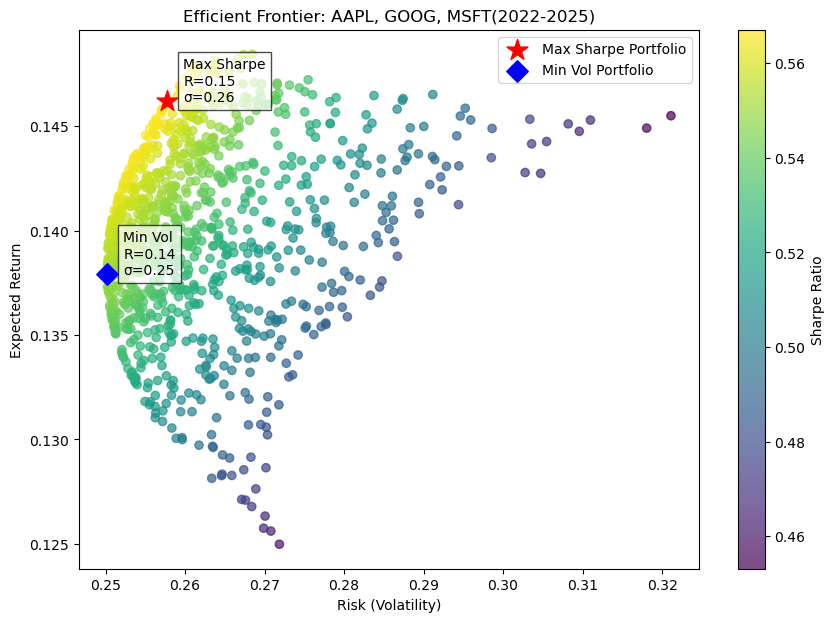

In [21]:
plt.figure(figsize=(10,7))
plt.scatter(results[0, :], results[1, :], c=results[2, :], cmap='viridis', alpha=0.7)
plt.colorbar(label='Sharpe Ratio')
plt.xlabel('Risk (Volatility)')
plt.ylabel('Expected Return')
plt.title('Efficient Frontier: AAPL, GOOG, MSFT(2022-2025)')

plt.scatter(optimal_risk, optimal_return, color='r', marker='*', s=250, label='Max Sharpe Portfolio')

plt.scatter(min_vol_risk, min_vol_return, color='b', marker='D', s=120, label='Min Vol Portfolio')

plt.text(optimal_risk+0.002, optimal_return,
        f'Max Sharpe\nR={optimal_return:.2f}\nσ={optimal_risk:.2f}',
        fontsize=10, color='black', bbox=dict(facecolor='white', alpha=0.7))

plt.text(min_vol_risk+0.002, min_vol_return,
        f'Min Vol\nR={min_vol_return:.2f}\nσ={min_vol_risk:.2f}',
        fontsize=10, color='black', bbox=dict(facecolor='white', alpha=0.7))

plt.legend()
plt.show()

10/05/2025 
Learning Reflection-Efficient Frontier Analysis (Day Summary)
Today's analysis of the efficient frontier using real market data for AAPL, GOOG, and MSFT (2022-2025) demonstrates the fundamental balance between risk and return in modern portfolio theory.

The Max Sharpe Portfolio achieves a risk-adjusted Sharpe ratio of approximately 0.57, with an expected annual return of 14.6% at a volatility of 25.8%.

Meanwhile, the Minimum Volatility Portfolio minimizes overall risk (σ≈0.25) while maintaining a stable expected return of 13.8%

Together, these results clearly illustrates that diversification enhances efficiency-investors can achieve better returns for a given level of risk by optimally combining assest.